# The CA1 population for the place-cell fit (Sec. 3.2, App. K)

Builds the CA1 rate maps behind the place-cell fit and shows the population before and after
each selection step, so that the choice of units is visible.

**Data.** The open-field CA1 recordings of Blackstad, Moser and Moser (2024), published with
Carpenter et al. (2024): five rats foraging in a 150 × 150 cm arena, tetrodes in dorsal CA1,
clusters cut with MClust. `data/ca1_events.npz` holds the tracking and spike times of the
whole release, extracted by `experimental_data/extract_ca1.py`, and `experimental_data/ca1.py`
documents the format and builds the rate maps.

**Selection**, in three steps.

1. *Duplicates.* The release holds 2729 cluster files and the source paper counts 1002 units,
   and the curated list is not in the release. Clusters nested in a larger cluster of the same
   session, sharing more than half their spikes, are dropped.
2. *Mean rate.* The source paper's criterion, between 1 and 10 Hz over the session.
3. *Spatial information.* The source paper did not filter on it. The fit models spatial
   structure, so units below 0.5 bits per spike are dropped. They stay in the gallery so the
   cut is visible.

**Preprocessing** follows the source paper: head position smoothed with a Gaussian of 3
samples, frames outside 6 to 60 cm/s discarded, 32 bins across the occupied extent (about
4.3 cm per bin). Rate maps are indexed `(unit, bins_x, bins_y)` like `data/gc_ratmaps.npy` and
are shown in arena coordinates.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / "notebooks" / "experimental_data"))
from ca1 import (  # noqa: E402
    border_score,
    load_events,
    place_fields,
    population_ratemaps,
    select_units,
    split_half_correlation,
)

EVENTS = REPO_ROOT / "data" / "ca1_events.npz"
OUTPUT = REPO_ROOT / "data" / "ca1_ratemaps.npz"
FIGURE_DIR = REPO_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

# RATE_RANGE is the source paper's criterion, INFO_THRESHOLD ours.
RATE_RANGE = (1.0, 10.0)  # Hz, mean over the session
INFO_THRESHOLD = 0.5  # bits per spike, Skaggs spatial information
N_BINS = 32
MAP_SIGMA = 1.0  # bins, smoothing of spike counts and occupancy before dividing
POSITION_SIGMA = 3.0  # samples
SPEED_RANGE = (6.0, 60.0)  # cm/s

# Field metrics, computed for every unit and stored with the rate maps. The candidate rule is
# reported for its count and not applied; the fit takes every spatially tuned unit of one rat.
FIELD_THRESHOLD = 0.2  # of peak rate, for delineating fields
FIELD_MIN_BINS = 9  # ~170 cm^2 at 4.3 cm bins
CANDIDATE_RULE = {"max_fields": 1, "max_border": 0.5, "min_stability": 0.5}

## Counts at each step

In [2]:
sessions, units = load_events(EVENTS)
animals = sorted({s.animal for s in sessions})

not_duplicate = np.array([i for i, u in enumerate(units) if u.duplicate_of < 0])
rate_passing = select_units(units, RATE_RANGE)


def per_animal(indices):
    return {a: int(sum(sessions[units[i].session].animal == a for i in indices)) for a in animals}


print(f"{len(sessions)} sessions, {len(units)} cluster files")
print(f"{len(not_duplicate):5d} after dropping nested duplicates   {per_animal(not_duplicate)}")
print(f"{len(rate_passing):5d} with mean rate in {RATE_RANGE} Hz     {per_animal(rate_passing)}")

114 sessions, 2729 cluster files
 2086 after dropping nested duplicates   {'24101': 367, '24116': 272, '25398': 703, '26019': 366, '26191': 378}
  425 with mean rate in (1.0, 10.0) Hz     {'24101': 98, '24116': 19, '25398': 151, '26019': 68, '26191': 89}


In [3]:
rates, occupancy, information = population_ratemaps(
    sessions, units, rate_passing, N_BINS, MAP_SIGMA, POSITION_SIGMA, SPEED_RANGE
)
selected = rate_passing[information >= INFO_THRESHOLD]
print(f"{len(selected):5d} with spatial information >= {INFO_THRESHOLD} bits/spike   {per_animal(selected)}")

  223 with spatial information >= 0.5 bits/spike   {'24101': 50, '24116': 12, '25398': 107, '26019': 24, '26191': 30}


## Where the criteria cut

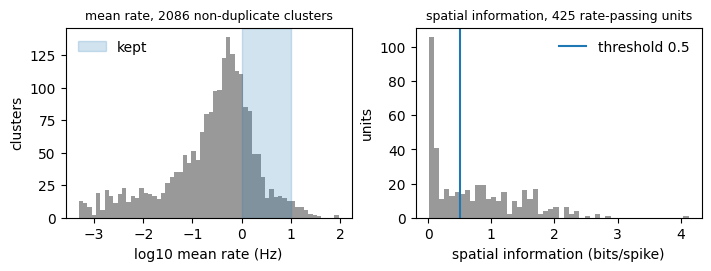

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(7, 2.6), layout="constrained")

all_rates = np.array([units[i].mean_rate for i in not_duplicate])
axs[0].hist(np.log10(all_rates[all_rates > 0]), bins=60, color="0.6")
axs[0].axvspan(*np.log10(RATE_RANGE), color="C0", alpha=0.2, label="kept")
axs[0].set_xlabel("log10 mean rate (Hz)")
axs[0].set_ylabel("clusters")
axs[0].set_title(f"mean rate, {len(not_duplicate)} non-duplicate clusters", fontsize=9)
axs[0].legend(frameon=False)

axs[1].hist(information, bins=50, color="0.6")
axs[1].axvline(INFO_THRESHOLD, color="C0", label=f"threshold {INFO_THRESHOLD}")
axs[1].set_xlabel("spatial information (bits/spike)")
axs[1].set_ylabel("units")
axs[1].set_title(f"spatial information, {len(rate_passing)} rate-passing units", fontsize=9)
axs[1].legend(frameon=False)
fig.savefig(FIGURE_DIR / "ca1_selection_histograms.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_selection_histograms.png", dpi=200, bbox_inches="tight")

## All rate-passing units, sorted by spatial information

Every unit that passes the mean-rate criterion, highest spatial information first. Panels below
the threshold are framed in red. Each map is scaled to its own peak, so the panels compare
field shape and not amplitude, and the title gives the peak rate.

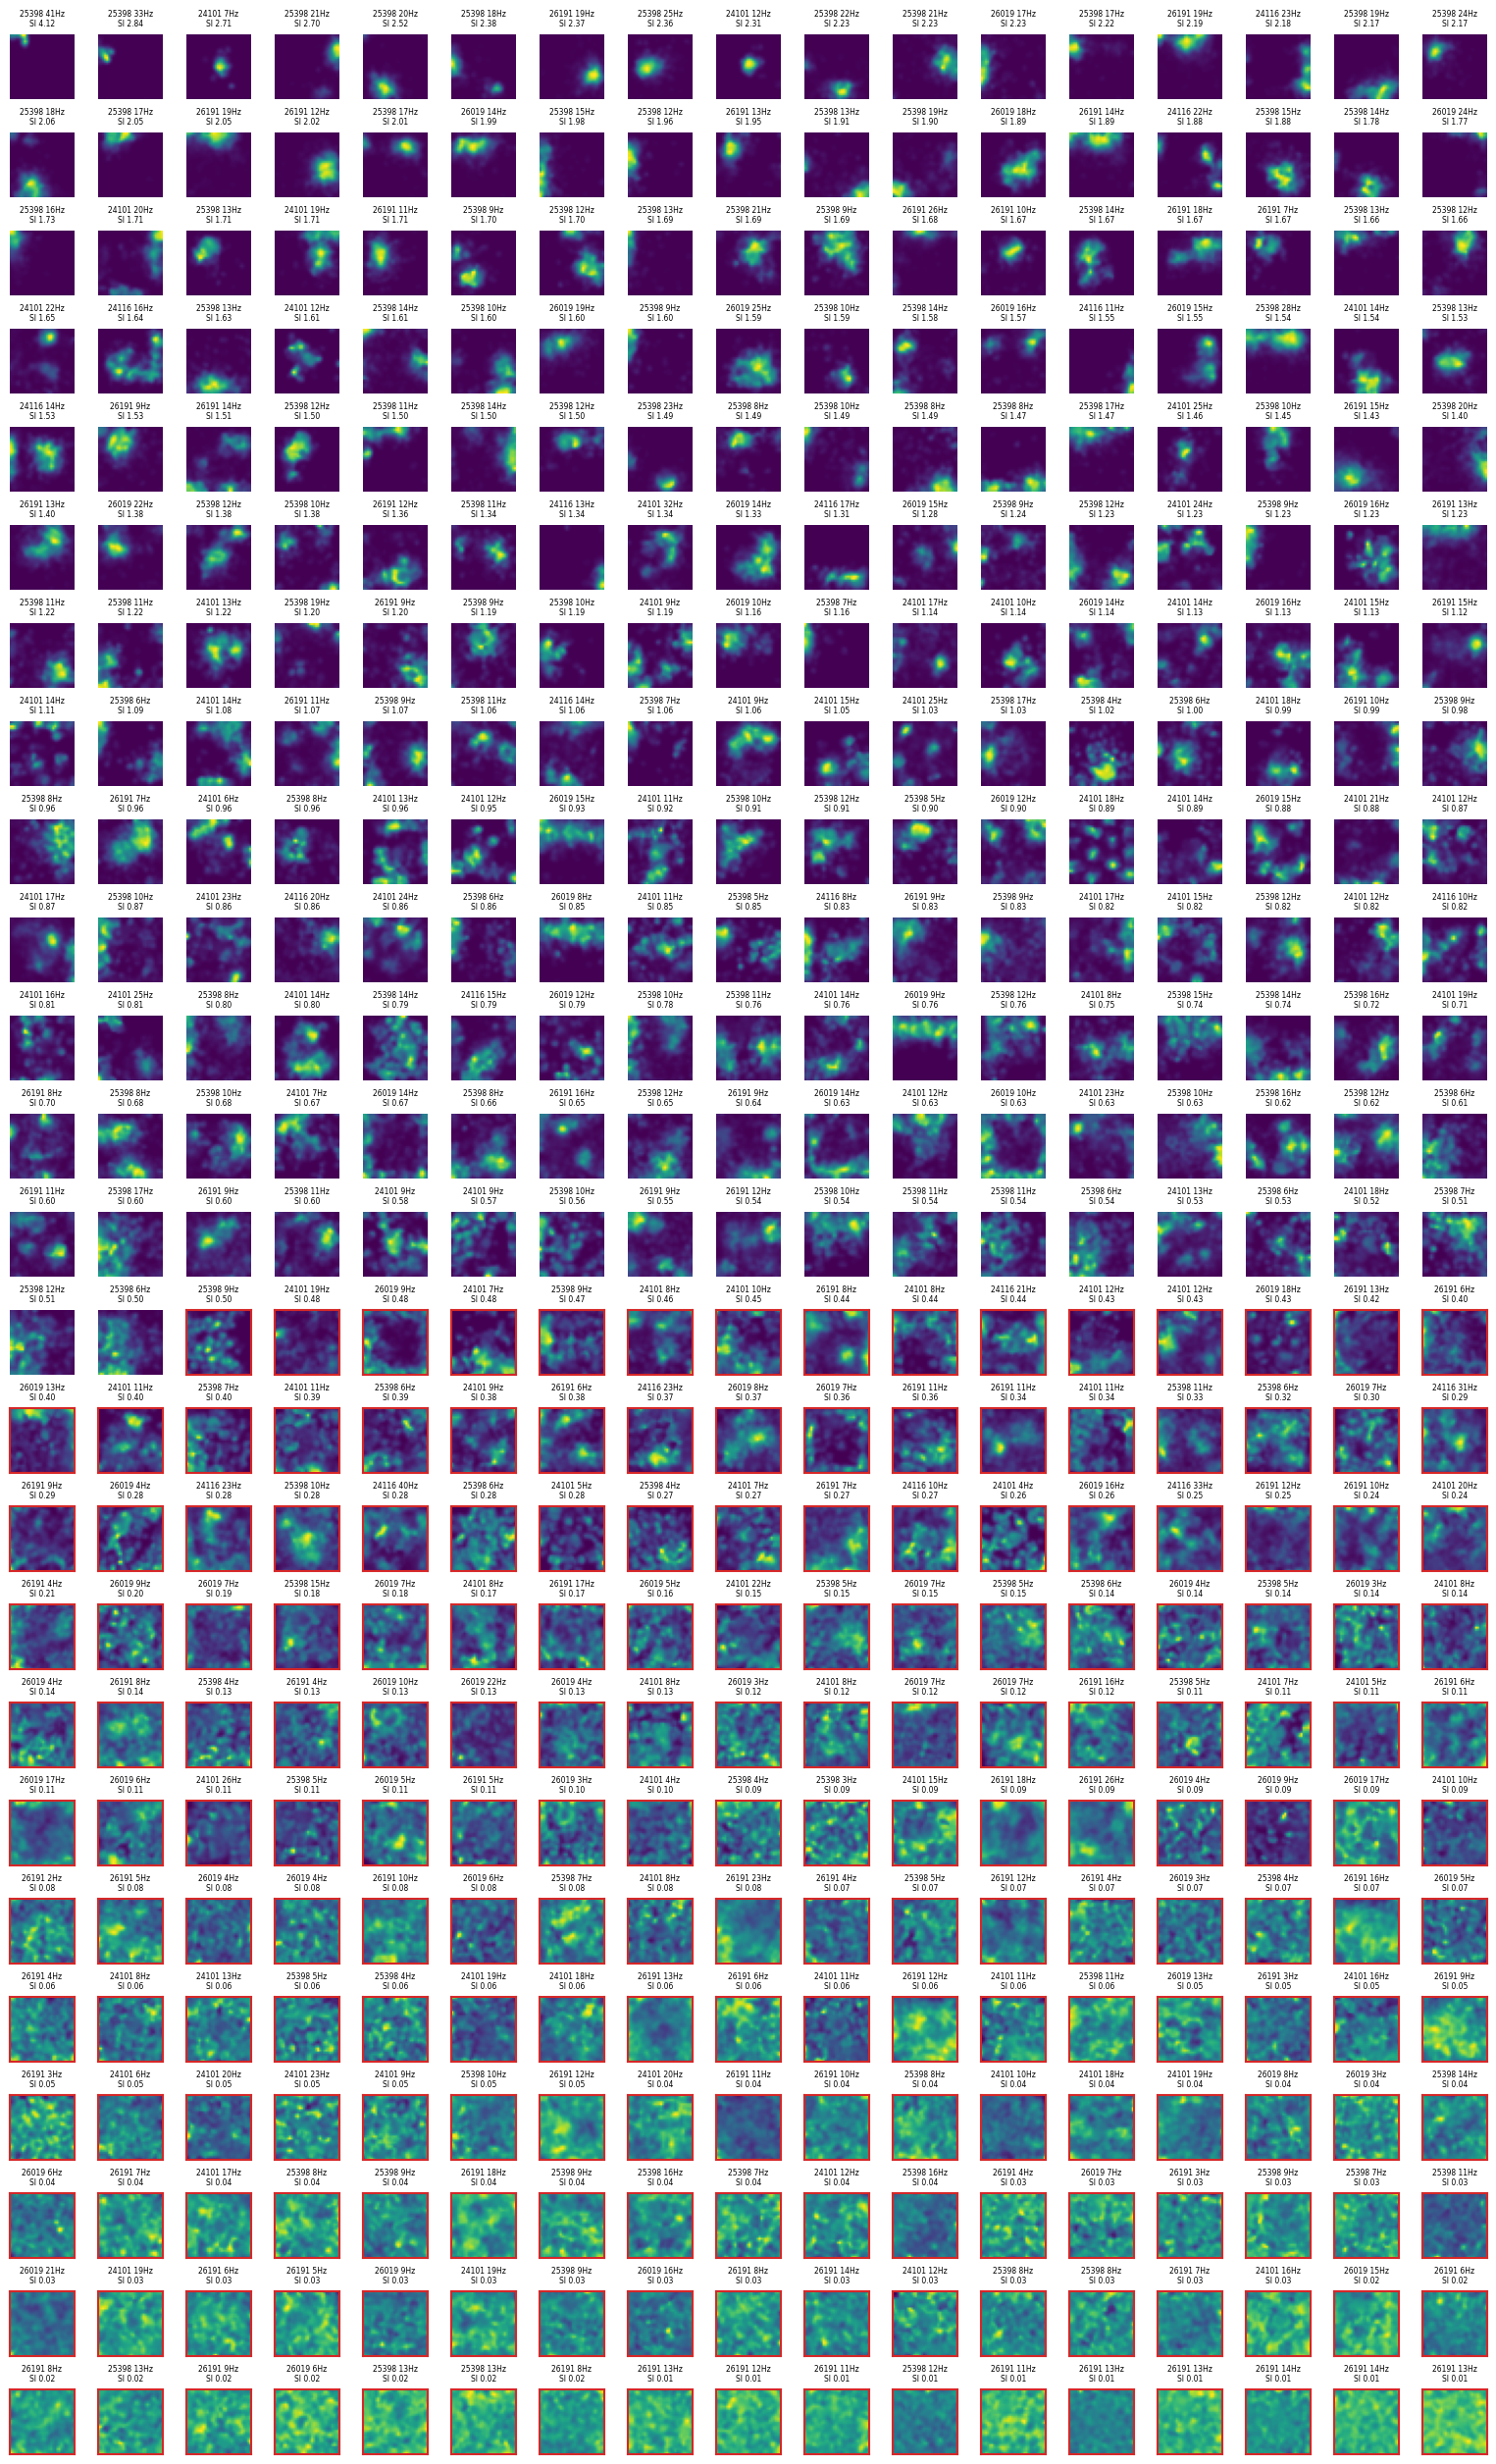

In [5]:
order = np.argsort(-information)
n_cols = 17
n_rows = int(np.ceil(len(order) / n_cols))
fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols * 0.9, n_rows * 1.0), layout="constrained")
for ax in axs.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_visible(False)
for ax, k in zip(axs.ravel(), order):
    ax.set_visible(True)
    m = rates[k]
    ax.imshow(m.T / np.nanmax(m), origin="lower", cmap="viridis", vmin=0, vmax=1)
    u = units[rate_passing[k]]
    is_kept = information[k] >= INFO_THRESHOLD
    ax.set_title(f"{sessions[u.session].animal} {np.nanmax(m):.0f}Hz\nSI {information[k]:.2f}", fontsize=5.5)
    for spine in ax.spines.values():
        spine.set_edgecolor("C3" if not is_kept else "none")
        spine.set_linewidth(1.5)
fig.savefig(FIGURE_DIR / "ca1_units_by_information.png", dpi=150, bbox_inches="tight")

## The selected population

The units that pass the information threshold, in the same order, on one color scale. The
scale is clipped at the 95th percentile of the peak rates, since three units above 30 Hz would
otherwise leave a typical 13 Hz unit faint. Panels that saturate are the ones above that
percentile.

223 units, peak rates 3.7..40.6 Hz, median 12.7, scale clipped at 24.1 Hz


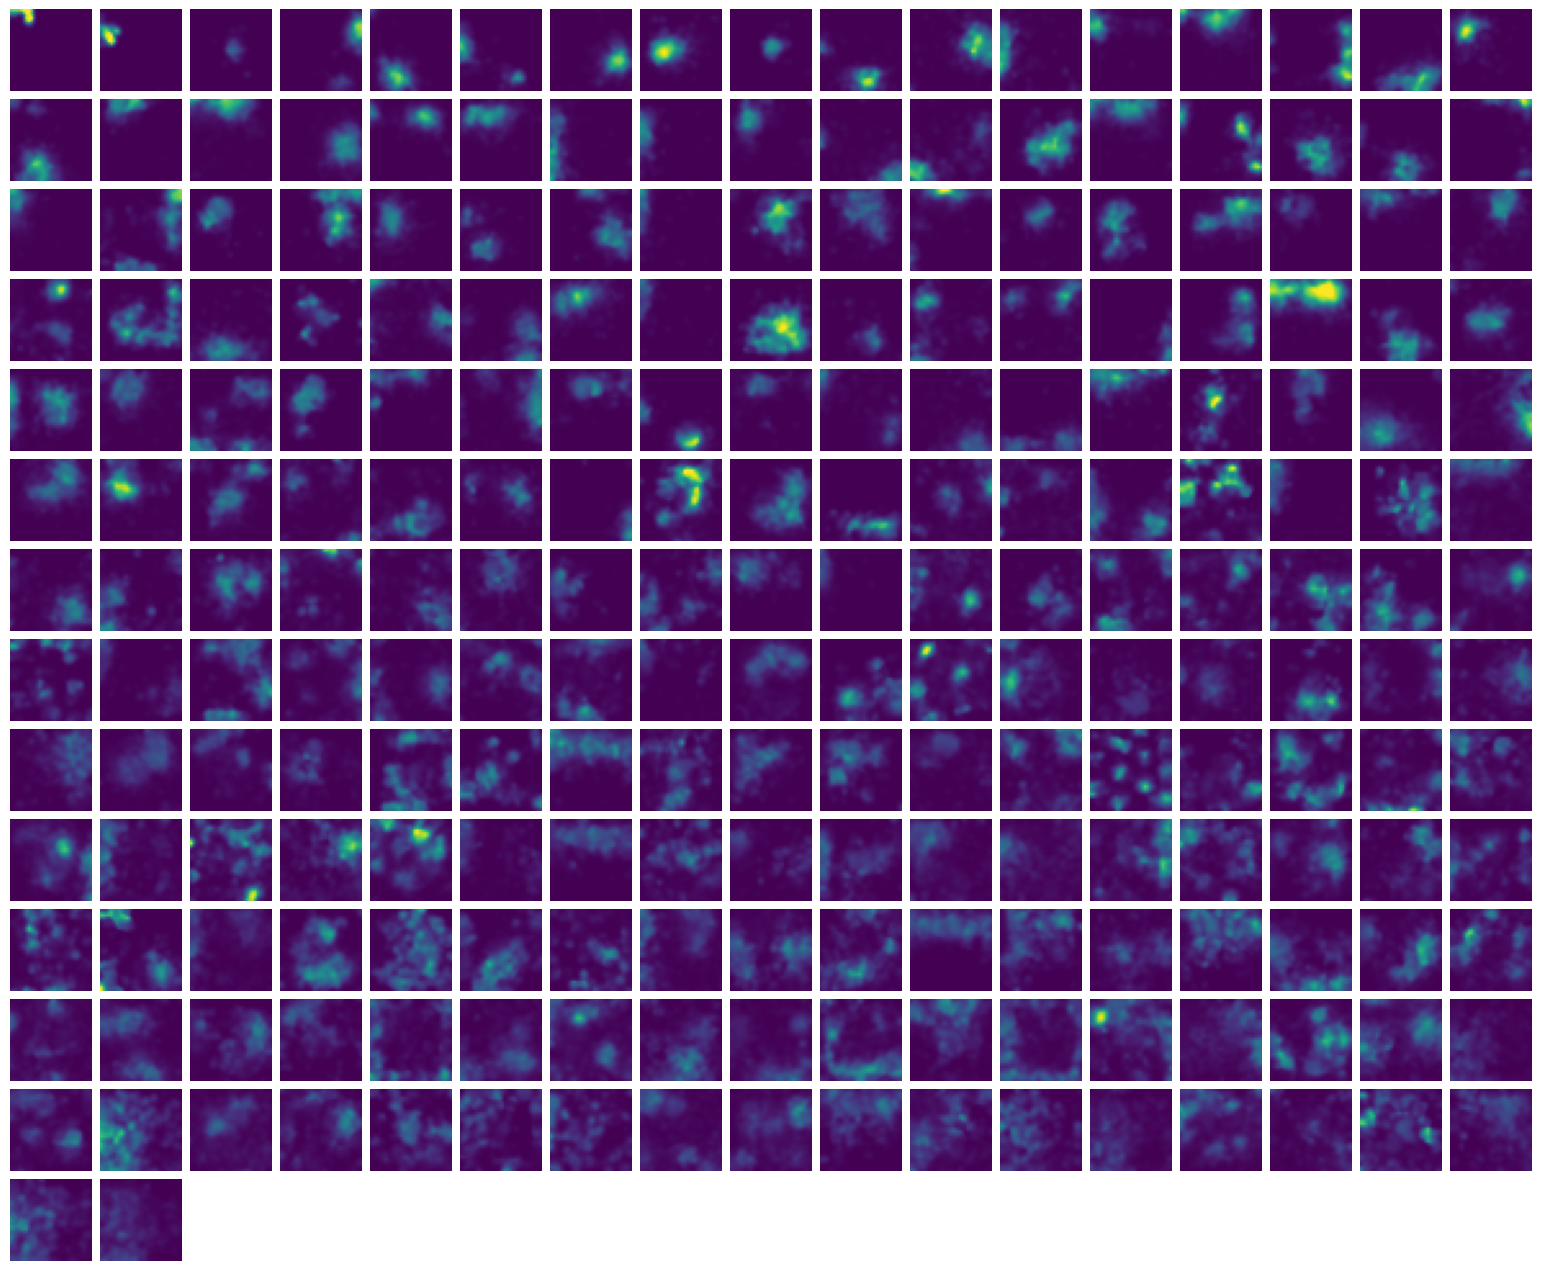

In [6]:
kept = order[information[order] >= INFO_THRESHOLD]
n_cols = 17
n_rows = int(np.ceil(len(kept) / n_cols))
peaks = np.nanmax(rates[kept], axis=(1, 2))
vmax = np.percentile(peaks, 95)
fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols * 0.9, n_rows * 0.9), layout="constrained")
for ax in axs.ravel():
    ax.axis("off")
for ax, k in zip(axs.ravel(), kept):
    ax.imshow(rates[k].T, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
fig.savefig(FIGURE_DIR / "ca1_selected_units.png", dpi=150, bbox_inches="tight")
print(f"{len(kept)} units, peak rates {peaks.min():.1f}..{peaks.max():.1f} Hz, median {np.median(peaks):.1f}, scale clipped at {vmax:.1f} Hz")

## One session

Occupancy after the speed filter and the session's rate-passing units on one color scale, to
show what a single recording contributes and how uneven the coverage is.

session 24101 2018-04-11 (neuralynx), 1216 s, 14 rate-passing units


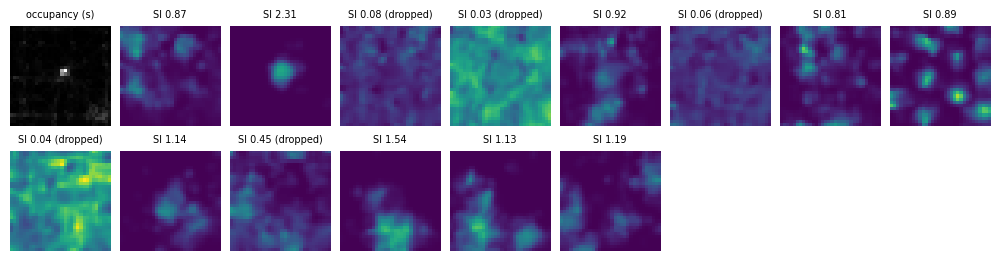

In [7]:
session_counts = {}
for i in rate_passing:
    session_counts[units[i].session] = session_counts.get(units[i].session, 0) + 1
example = max(session_counts, key=session_counts.get)
members = [k for k, i in enumerate(rate_passing) if units[i].session == example]
s = sessions[example]
print(f"session {s.animal} {s.date} ({s.system}), {s.duration:.0f} s, {len(members)} rate-passing units")

n_cols = min(len(members) + 1, 9)
n_rows = int(np.ceil((len(members) + 1) / n_cols))
vmax = np.nanmax(rates[members])
fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.1, n_rows * 1.25), layout="constrained")
axs = np.atleast_1d(axs).ravel()
for ax in axs:
    ax.axis("off")
axs[0].imshow(occupancy[members[0]].T, origin="lower", cmap="gray")
axs[0].set_title("occupancy (s)", fontsize=7)
for ax, k in zip(axs[1:], members):
    ax.imshow(rates[k].T, origin="lower", cmap="viridis", vmin=0, vmax=vmax)
    is_kept = information[k] >= INFO_THRESHOLD
    ax.set_title(f"SI {information[k]:.2f}" + ("" if is_kept else " (dropped)"), fontsize=7)
fig.savefig(FIGURE_DIR / "ca1_example_session.png", dpi=150, bbox_inches="tight")

## The selected population, each map at its own peak

The same units and order, scaled per unit to compare field shape. Peak rates span 3.7 to
40.6 Hz with a median of 12.7 Hz.

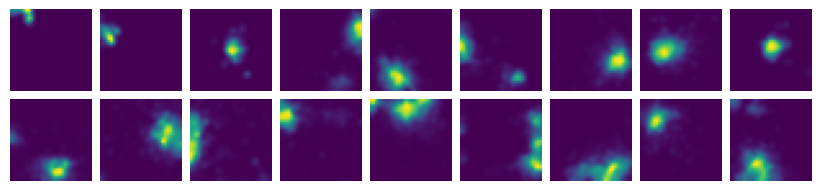

In [8]:
fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols * 0.9, n_rows * 0.9), layout="constrained")
for ax in axs.ravel():
    ax.axis("off")
for ax, k in zip(axs.ravel(), kept):
    ax.imshow(rates[k].T / np.nanmax(rates[k]), origin="lower", cmap="viridis", vmin=0, vmax=1)
fig.savefig(FIGURE_DIR / "ca1_selected_units_normalised.png", dpi=150, bbox_inches="tight")

## Field structure

The information threshold keeps border-like and multi-field units alongside single-field
place cells. Three metrics make that visible:

- **Number of fields.** Contiguous regions above 20 % of the peak rate covering at least 9 bins.
- **Border score** (Solstad et al. 2008), $b = (c_M - d_M)/(c_M + d_M)$: 1 for a field along a
  whole wall, −1 for one in the center. Border cells conventionally score above 0.5.
- **Split-half stability.** Pearson correlation between the rate maps of the two halves of the
  session, over bins visited in both.

The metrics are computed for every rate-passing unit and stored with the rate maps. The
candidate rule, a single field with a border score of at most 0.5 and a stability of at least
0.5, is reported for its count and not applied. The place-cell fit of the paper
(`fit_place_cells`) takes every spatially tuned unit of one rat and applies no field criterion.

fields among the kept units: {1: 97, 2: 64, 3: 42, 4: 13, 5: 6, 10: 1}
border score > 0.5: 50   stability < 0.5: 11


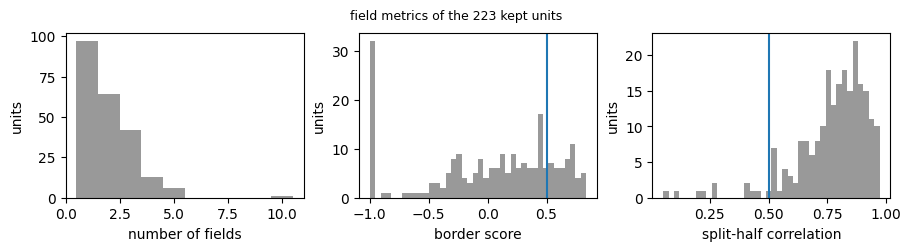

In [9]:
fields = [place_fields(r, FIELD_THRESHOLD, FIELD_MIN_BINS) for r in rates]
n_fields = np.array([f.max() for f in fields])
border = np.array([border_score(r, f) for r, f in zip(rates, fields)])
stability = split_half_correlation(sessions, units, rate_passing, N_BINS, MAP_SIGMA, POSITION_SIGMA, SPEED_RANGE)

kept_mask = information >= INFO_THRESHOLD
print("fields among the kept units:", {int(n): int((n_fields[kept_mask] == n).sum()) for n in np.unique(n_fields[kept_mask])})
print(f"border score > 0.5: {int((border[kept_mask] > 0.5).sum())}   stability < 0.5: {int((stability[kept_mask] < 0.5).sum())}")

fig, axs = plt.subplots(1, 3, figsize=(9, 2.4), layout="constrained")
axs[0].hist(n_fields[kept_mask], bins=np.arange(0.5, n_fields[kept_mask].max() + 1.5), color="0.6")
axs[0].set_xlabel("number of fields")
axs[1].hist(border[kept_mask][np.isfinite(border[kept_mask])], bins=40, color="0.6")
axs[1].axvline(CANDIDATE_RULE["max_border"], color="C0")
axs[1].set_xlabel("border score")
axs[2].hist(stability[kept_mask][np.isfinite(stability[kept_mask])], bins=40, color="0.6")
axs[2].axvline(CANDIDATE_RULE["min_stability"], color="C0")
axs[2].set_xlabel("split-half correlation")
for ax in axs:
    ax.set_ylabel("units")
fig.suptitle(f"field metrics of the {kept_mask.sum()} kept units", fontsize=9)
fig.savefig(FIGURE_DIR / "ca1_field_metrics.svg", bbox_inches="tight")
fig.savefig(FIGURE_DIR / "ca1_field_metrics.png", dpi=200, bbox_inches="tight")

### Kept units by category

Each map at its own peak, fields outlined. The categories are exclusive, in this order:
border-like (score above 0.5), unstable (split-half below 0.5), multi-field, single-field.

candidate rule {'max_fields': 1, 'max_border': 0.5, 'min_stability': 0.5}: 71 units   {'24101': 9, '24116': 3, '25398': 34, '26019': 11, '26191': 14}
single field, border kept: 97 units; of which stability >= 0.5: 94
  with up to 2 fields: 116 units
  with up to 3 fields: 149 units


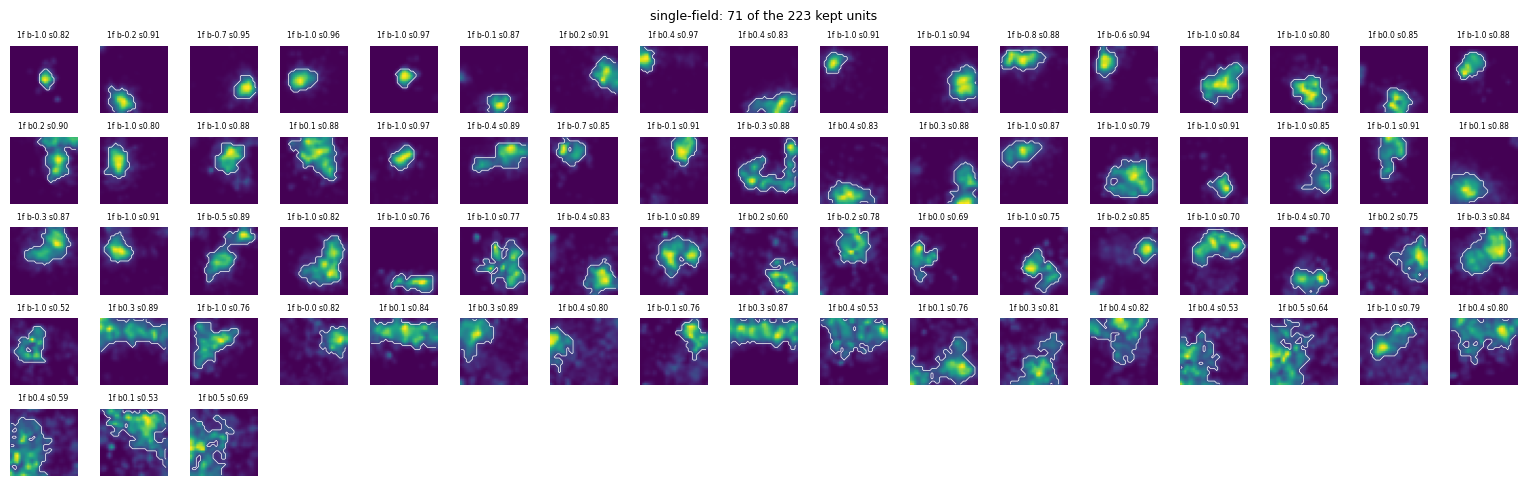

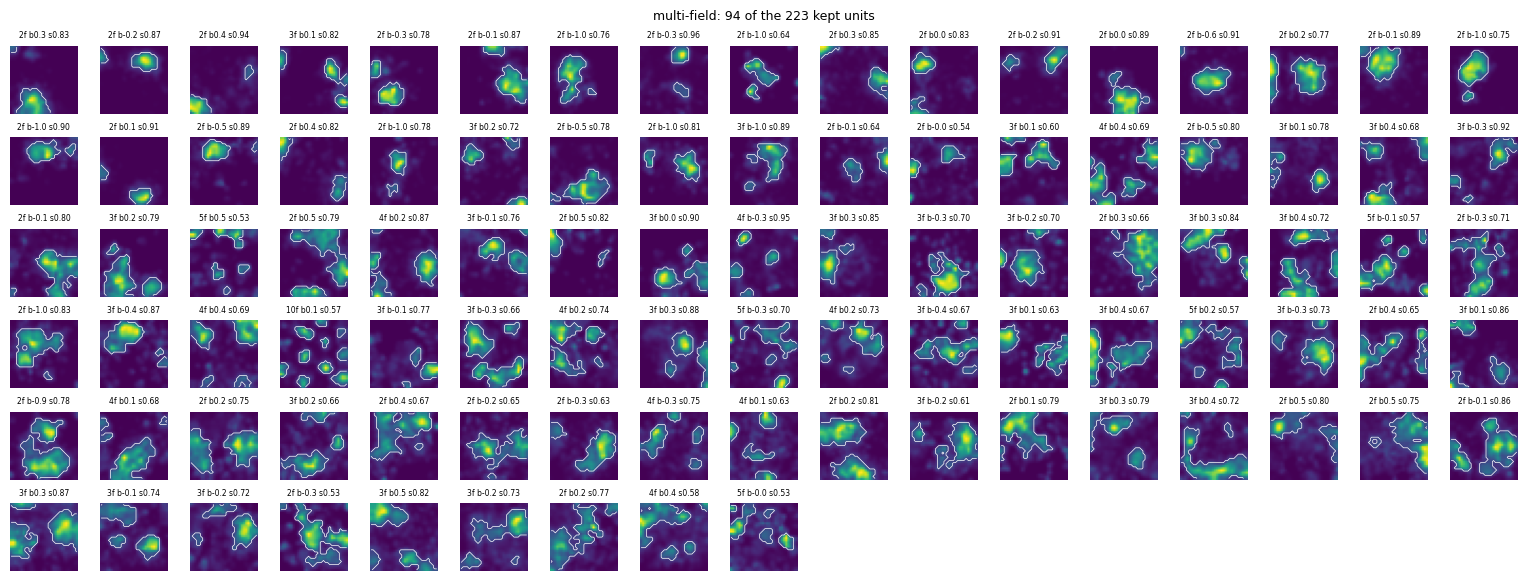

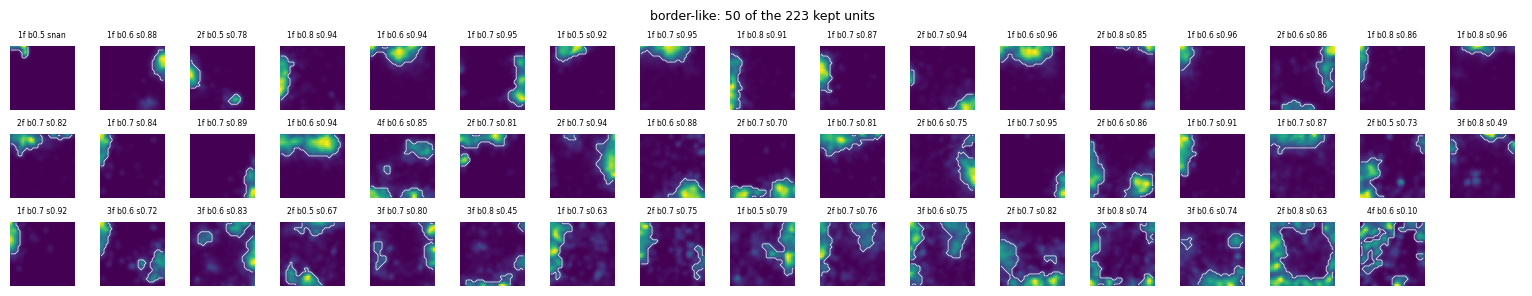

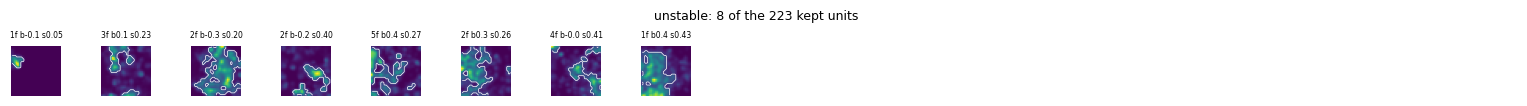

In [10]:
category = np.full(len(rate_passing), "single-field", dtype=object)
category[n_fields >= 2] = "multi-field"
category[~(stability >= CANDIDATE_RULE["min_stability"])] = "unstable"
category[border > CANDIDATE_RULE["max_border"]] = "border-like"
category[n_fields == 0] = "no field"

for name in ["single-field", "multi-field", "border-like", "unstable", "no field"]:
    members = kept[category[kept] == name]
    if len(members) == 0:
        continue
    n_cols = 17
    n_rows = int(np.ceil(len(members) / n_cols))
    fig, axs = plt.subplots(n_rows, n_cols, figsize=(n_cols * 0.9, n_rows * 0.95), layout="constrained")
    for ax in np.atleast_1d(axs).ravel():
        ax.axis("off")
    for ax, k in zip(np.atleast_1d(axs).ravel(), members):
        ax.imshow(rates[k].T / np.nanmax(rates[k]), origin="lower", cmap="viridis", vmin=0, vmax=1)
        ax.contour(fields[k].T > 0, levels=[0.5], colors="w", linewidths=0.5)
        ax.set_title(f"{n_fields[k]}f b{border[k]:.1f} s{stability[k]:.2f}", fontsize=5.5)
    fig.suptitle(f"{name}: {len(members)} of the {len(kept)} kept units", fontsize=9)
    fig.savefig(FIGURE_DIR / f"ca1_kept_{name.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")

rule = CANDIDATE_RULE
candidate = kept_mask & (n_fields >= 1) & (n_fields <= rule["max_fields"]) & ~(border > rule["max_border"]) & (stability >= rule["min_stability"])
print(f"candidate rule {rule}: {candidate.sum()} units   {per_animal(rate_passing[candidate])}")
single = kept_mask & (n_fields == 1)
print(f"single field, border kept: {single.sum()} units; of which stability >= {rule['min_stability']}: {(single & (stability >= rule['min_stability'])).sum()}")
for max_fields in (2, 3):
    alt = kept_mask & (n_fields >= 1) & (n_fields <= max_fields) & ~(border > rule["max_border"]) & (stability >= rule["min_stability"])
    print(f"  with up to {max_fields} fields: {alt.sum()} units")

## Save

`data/ca1_ratemaps.npz` holds the rate maps of the kept units in the layout of `gc_ratmaps`,
the provenance of every unit, the three field metrics and the parameters above. The file is
not tracked. `fit_place_cells` builds its population from the events file directly.

In [11]:
chosen = [units[i] for i in selected]
np.savez_compressed(
    OUTPUT,
    ratemaps=rates[information >= INFO_THRESHOLD].astype(np.float32),
    occupancy=occupancy[information >= INFO_THRESHOLD].astype(np.float32),
    information=information[information >= INFO_THRESHOLD],
    n_fields=n_fields[information >= INFO_THRESHOLD],
    border_score=border[information >= INFO_THRESHOLD],
    stability=stability[information >= INFO_THRESHOLD],
    animal=np.array([sessions[u.session].animal for u in chosen]),
    date=np.array([sessions[u.session].date for u in chosen]),
    tetrode=np.array([u.tetrode for u in chosen]),
    cluster=np.array([u.cluster for u in chosen]),
    mean_rate=np.array([u.mean_rate for u in chosen]),
    rate_range=np.array(RATE_RANGE),
    info_threshold=INFO_THRESHOLD,
    n_bins=N_BINS,
    map_sigma=MAP_SIGMA,
    position_sigma=POSITION_SIGMA,
    speed_range=np.array(SPEED_RANGE),
    field_threshold=FIELD_THRESHOLD,
    field_min_bins=FIELD_MIN_BINS,
)
saved = np.load(OUTPUT)
print(f"{OUTPUT.name}: ratemaps {saved['ratemaps'].shape}, {OUTPUT.stat().st_size / 1e6:.1f} MB")

ca1_ratemaps.npz: ratemaps (223, 32, 32), 0.9 MB
